# CITS5508 - Assignment 2 2026

Dipika Choudhury - 23779727

## Part 1 - Ensemble Learning for Heart Disease Prediction

### 1. Load the dataset and assign appropriate column names.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

heart = pd.read_csv(
    "processed.cleveland.data",
    names=column_names,
    na_values="?"
)

heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print("Original shape:", heart.shape)

print("\nMissing values:")
print(heart.isna().sum())

heart = heart.dropna()

print("\nShape after dropping the values that are missing:", heart.shape)

Original shape: (303, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Shape after dropping the values that are missing: (297, 14)


### Briefly describe the dataset:
### (a) How many examples are there? What does each example represent?
There are 303 examples in the original dataset that has 14 columns, and as shown above, there's 297 remaining examples after dropping missing values. Each one of the examples represent one record of a patient from the Cleveland Heart Disease database. The columns illustrate information about patients like age, sex, chest pain type, resting blood pressure, serum cholesterol, fasting blood sugar, maximum heart rate achieved, among other pieces of information.

### (b) How many features are there? Which are numeric and which are categorical?
As mentioned, there are 14 columns. Out of these, 1 is the target and the other 13 are the features. As per the 'Variables Table', the numerical or integer type features are: age, trestbps, chol, thalaxh, oldpeak, and ca. On the other hand, the categorical features are sex, cp, fbs, restecg, exang, slope, and thal.

### (c) Describe the target attribute (num). The original target indicates the severity of heart disease on an integer scale from zero to four. For this assignment, binarise the target: 0 indicates absence of disease, and any value greater than 0 indicates presence.
The original target attribute is num, which records heart disease severity from 0 to 4. 0 would mean there is no heart disease, while a value of 1-4 shows increasing severity of heart disease. Since this assignment treats the problem as binary classification, I created a new target variable where 0 represents absence of heart disease and 1 represents presence of heart disease. This step is shown in the code cell below.

In [4]:
heart["target"] = (heart["num"] > 0).astype(int)

heart[["num", "target"]].head(10)

,num,target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


### 2. Split the dataset into a training and testing set. Use 80% of the data for training, and 20% for testing. Make sure to stratify your split.

In [5]:
from sklearn.model_selection import train_test_split

X = heart.drop(columns=["num", "target"])
y = heart["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", X_train.shape[0])
print("Test examples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

print("Full dataset distribution:")
print(y.value_counts(normalize=True))

print("\nTraining set distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest set distribution:")
print(y_test.value_counts(normalize=True))

Training examples: 237
Test examples: 60
Number of features: 13
Full dataset distribution:
target
0    0.538721
1    0.461279
Name: proportion, dtype: float64

Training set distribution:
target
0    0.540084
1    0.459916
Name: proportion, dtype: float64

Test set distribution:
target
0    0.533333
1    0.466667
Name: proportion, dtype: float64


Just to double check that stratification worked, I checked the class proportions in the full dataset, training set and test set. As you can see, the proportion of patients with and without heart disease were very similar across all three, showing that the 80/20 split preserved the target class balance.

### 3. Fit a single Decision Tree classifier using scikit-learn as a baseline and evaluate its performance on the test set.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Accuracy": [accuracy_score(y_test, y_pred_dt)],
    "Precision": [precision_score(y_test, y_pred_dt)],
    "Recall": [recall_score(y_test, y_pred_dt)],
    "F1-score": [f1_score(y_test, y_pred_dt)]
})

dt_results

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7,0.692308,0.642857,0.666667


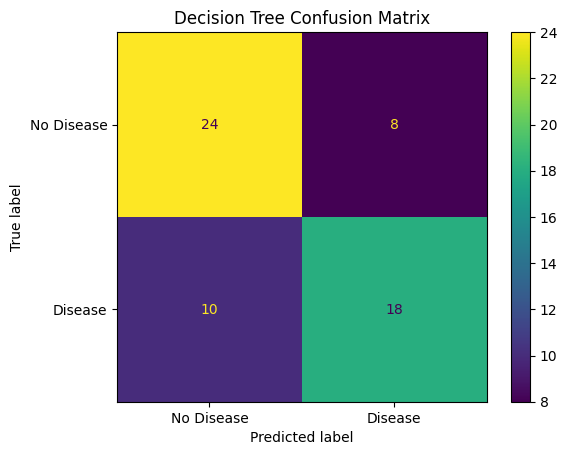

In [7]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No Disease", "Disease"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

To evaluate the performance of my Decision Tree model, I trained it using the training set and then evaluated on the test set. The metrics I chose were accuracy, precision, recall, and F1-score. 

It got an accuracy of 0.7, which means that 70% of the test examples were classified correctly. The precision score was 0.692, meaning that when the model predicted heart disease, it was correct around 69.2% of the time. The recall score was 0.643, meaning that the model correctly identified about 64.3% of the actual heart disease cases. Finally, the F1-score was 0.667, which gave a combined measure of precision and recall.

The confusion matrix provided a bit more detail by showing how many patients were correctly and incorrectly classified as having or not having heart disease. This was useful to help with evaluation because the metrics above don't specifically illustrate these issues. The model correctly predicted no-disease or disease more often than it incorrectly gave false positives or negatives.

### 4. Fit two further ensemble models using scikit-learn:

#### - A Random Forest classifier with 500 estimators.
#### - An AdaBoost classifier with 500 estimators.

In [8]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

ada_model = AdaBoostClassifier(
    n_estimators=500,
    random_state=42
)

rf_model.fit(X_train, y_train)
ada_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_ada = ada_model.predict(X_test)

ensemble_results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada)
    ],
    "Precision": [
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada)
    ],
    "Recall": [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada)
    ]
})

ensemble_results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.867,0.885,0.821,0.852
1,AdaBoost,0.850,0.828,0.857,0.842


### 5. Combine your models from the previous steps in a soft-voting Voting Classifier.

In [9]:
voting_model = VotingClassifier(
    estimators=[
        ("decision_tree", dt_model),
        ("random_forest", rf_model),
        ("adaboost", ada_model)
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)

y_pred_voting = voting_model.predict(X_test)

voting_results = pd.DataFrame({
    "Model": ["Voting Classifier"],
    "Accuracy": [accuracy_score(y_test, y_pred_voting)],
    "Precision": [precision_score(y_test, y_pred_voting)],
    "Recall": [recall_score(y_test, y_pred_voting)],
    "F1-score": [f1_score(y_test, y_pred_voting)]
})

voting_results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Voting Classifier,0.717,0.72,0.643,0.679


### 6. Compare the performance of all four models (the decision tree baseline, the Random Forest, the AdaBoost classifier, and the voting classifier) on the test set:

### (a) Create a table of precision, recall, and F1-scores for each model.

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "Voting Classifier"
    ],
    "Precision": [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_ada),
        precision_score(y_test, y_pred_voting)
    ],
    "Recall": [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_ada),
        recall_score(y_test, y_pred_voting)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_ada),
        f1_score(y_test, y_pred_voting)
    ]
})

model_results.round(3)

,Model,Precision,Recall,F1-score
0,Decision Tree,0.692,0.643,0.667
1,Random Forest,0.885,0.821,0.852
2,AdaBoost,0.828,0.857,0.842
3,Voting Classifier,0.720,0.643,0.679


### (b) Display a confusion matrix for each model.

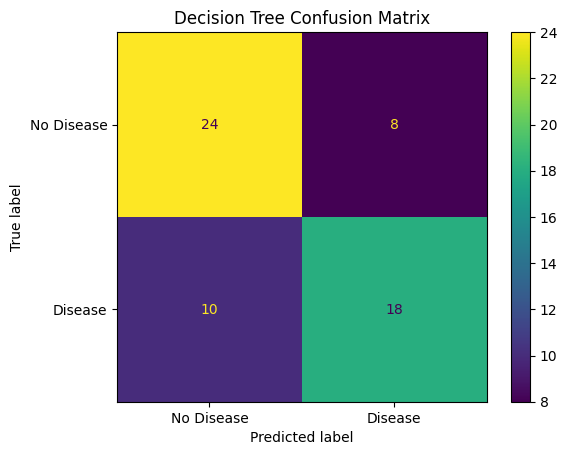

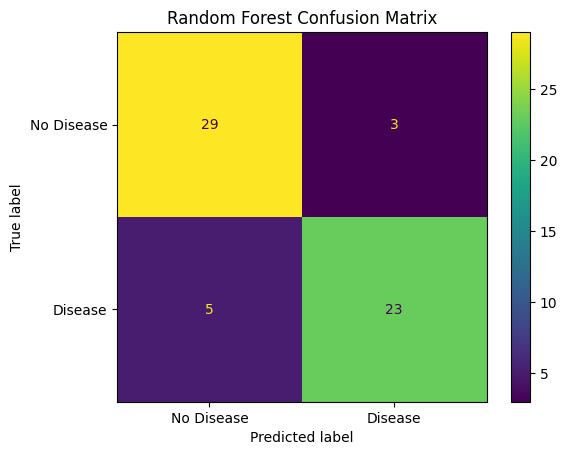

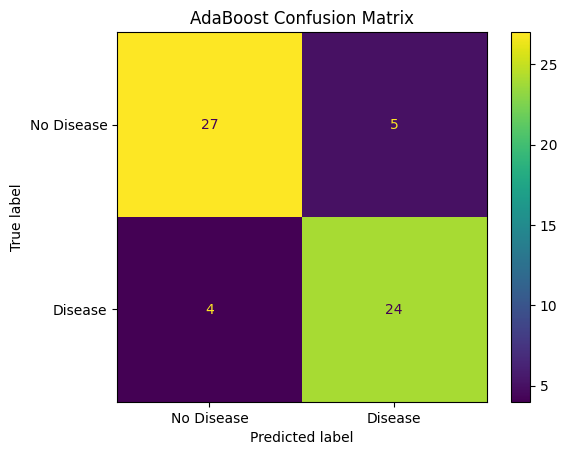

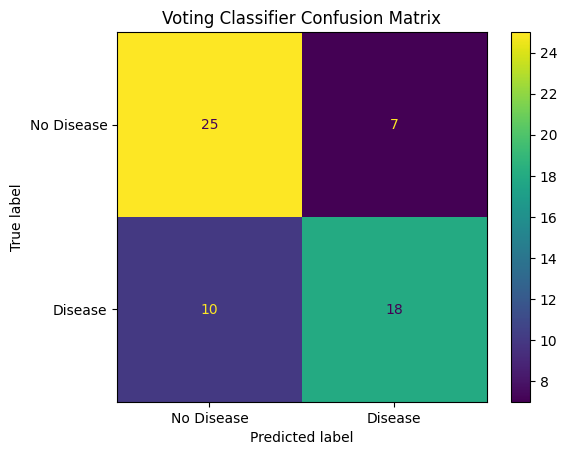

In [11]:
models_and_predictions = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada,
    "Voting Classifier": y_pred_voting
}

for model_name, predictions in models_and_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease", "Disease"]
    )

    disp.plot()
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

The Random Forest and AdaBoost models performed better than the single Decision Tree baseline. The Decision Tree had the lowest F1-score of 0.667, suggesting that it was less effective at balancing precision and recall.

The Random Forest achieved the highest precision of 0.885 and the highest F1-score of 0.852. This means that when it predicted heart disease, it was usually correct, and it also maintained a strong balance between precision and recall. AdaBoost achieved the highest recall of 0.857, meaning it identified the largest proportion of actual heart disease cases.

The Voting Classifier did not improve on the individual ensemble models. Its F1-score of 0.679 was only slightly better than the Decision Tree baseline and much lower than Random Forest and AdaBoost. This suggests that combining the models by soft voting did not necessarily produce a better classifier in this case.

### 7. Plot the feature importances of your Random Forest. Briefly comment on which features contribute most strongly to predictions, and whether this matches what you would expect.

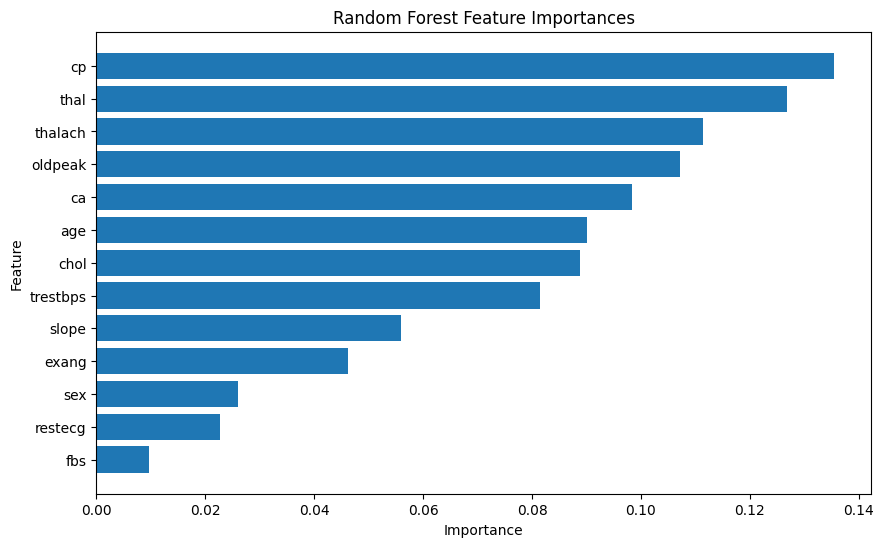

In [12]:
feature_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importances = feature_importances.sort_values(
    by="Importance",
    ascending=False
)

feature_importances

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importances["Feature"],
    feature_importances["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importances")
plt.show()

The Random Forest feature importance plot shows that `cp`, `thal`, `thalach`, `oldpeak` and `ca` contributed most strongly to the model's predictions.

This broadly matches what I would expect because these features are closely related to heart disease indicators. `cp` represents chest pain type, which is directly relevant because chest pain symptoms can be associated with heart disease. `thalach`, the maximum heart rate achieved, and `oldpeak`, ST depression induced by exercise, both relate to exercise test results and may indicate how the heart responds under stress. `ca`, the number of major vessels coloured by fluoroscopy, is also clinically relevant because it relates to visible vessel involvement. `thal` also appears important, although it is an encoded categorical variable rather than a continuous measurement.

Features such as `fbs`, `restecg` and `sex` had lower importance in this model. This does not mean they are useless or medically irrelevant, but in this fitted Random Forest they contributed less to reducing prediction error compared with the higher-ranked variables.

Overall, the feature importance ranking seems reasonable because the strongest features are mostly symptom-related or test-related variables that would be expected to help distinguish between patients with and without heart disease.

### 8. Comment on your results in detail. Investigate the following ideas:

#### (a) How do the models compare to each other? Which model performs best? Is this what you expected?

Overall, the ensemble models performed better than the single Decision Tree baseline. The Decision Tree had the weakest performance, with precision of 0.692, recall of 0.643 and an F1-score of 0.667. This suggests that the single tree was less effective at generalising to the test set.

The Random Forest performed best overall based on F1-score. It achieved precision of 0.885, recall of 0.821 and an F1-score of 0.852. This means it had the strongest balance between precision and recall. It also had the highest precision, meaning that when it predicted heart disease, it was correct more often than the other models.

AdaBoost also performed strongly, with precision of 0.828, recall of 0.857 and an F1-score of 0.842. Although its F1-score was slightly lower than the Random Forest, it had the highest recall. This means AdaBoost identified the largest proportion of actual heart disease cases. In a medical prediction problem, this is important because a false negative would mean a patient with heart disease was predicted as not having heart disease.

The Voting Classifier did not improve the results. It achieved precision of 0.720, recall of 0.643 and an F1-score of 0.679. This was only slightly better than the Decision Tree and much lower than the Random Forest and AdaBoost models. I expected the Voting Classifier to possibly perform better because it combines several models, but this did not happen here. One possible reason is that the weaker Decision Tree model may have reduced the quality of the average probability predictions used in soft voting.

Overall, the Random Forest was the best model based on F1-score, while AdaBoost was best based on recall. This was mostly expected because ensemble methods often perform better than a single decision tree.

### (b) Bagging and boosting reduce different sources of error. Which type of ensemble works better here, and why might that be?


Random Forest is a bagging method. It builds many decision trees using different bootstrap samples of the training data and combines their predictions. This mainly helps reduce variance, because the final prediction is less dependent on one individual tree.

AdaBoost is a boosting method. It builds models sequentially, with later models focusing more on examples that previous models classified incorrectly. This can help reduce bias and improve performance on difficult examples.

In my results, both bagging and boosting worked much better than the single Decision Tree. Random Forest had the highest F1-score, while AdaBoost had the highest recall. This suggests that bagging worked slightly better overall for this dataset because Random Forest had the best balance between precision and recall. However, boosting was also very competitive and may be preferred if the main aim is to reduce false negatives and detect as many actual heart disease cases as possible.

Since the dataset is fairly small, the Random Forest may have benefited from averaging many trees and reducing the instability that a single decision tree can have. This may explain why it performed slightly better overall than AdaBoost.

### (c) What are the advantages and disadvantages of using an ensemble method over the decision tree baseline?

The main advantage of the ensemble methods is that they performed better than the single Decision Tree. Both Random Forest and AdaBoost achieved much higher precision, recall and F1-scores than the baseline. This shows that combining multiple learners can create a stronger and more reliable model than relying on one decision tree.

Another advantage is that ensemble models are usually less sensitive to the specific training data. A single Decision Tree can overfit by creating splits that work well for the training set but do not generalise well to unseen data. Random Forest reduces this problem by averaging many trees, while AdaBoost improves performance by focusing on examples that are harder to classify.

However, ensemble methods also have disadvantages. They are less interpretable than a single Decision Tree because their predictions come from many trees or learners rather than one simple model. They can also take longer to train and may be harder to explain clearly. This matters in a medical-style prediction problem, where interpretability can be important.

Overall, the ensemble models gave better predictive performance, but this came at the cost of reduced simplicity and interpretability. The Decision Tree baseline was easier to understand, but the Random Forest and AdaBoost models were more accurate and reliable on the test set.

## Part 2 - Clustering of Faces

### 1. Load the Olivetti Faces dataset using the code above.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

data, targets = fetch_olivetti_faces(return_X_y=True)

print("Data shape:", data.shape)
print("Targets shape:", targets.shape)
print("Number of classes:", len(np.unique(targets)))

Data shape: (400, 4096)
Targets shape: (400,)
Number of classes: 40


### Briefly describe the dataset:

### (a) How many examples are there? What does each example represent?

The Olivetti Faces dataset contains 400 examples. Each example represents one greyscale face image of a person. There are 40 different classes in the dataset, where each class represents a different person. Since there are 400 images and 40 classes, there are 10 images per person.

### (b) Describe the features. How many features are there, and what does each feature represent?

Each example has 4096 features. This is because each face image is originally 64 × 64 pixels, and 64 × 64 = 4096. The images are stored in the dataset as flattened arrays, so each row contains the pixel values for one image. Each feature represents the intensity value of one pixel in the greyscale image.

### 2. Sample a random example from each class and display the images in a grid. Ensure each image is labelled with its class.

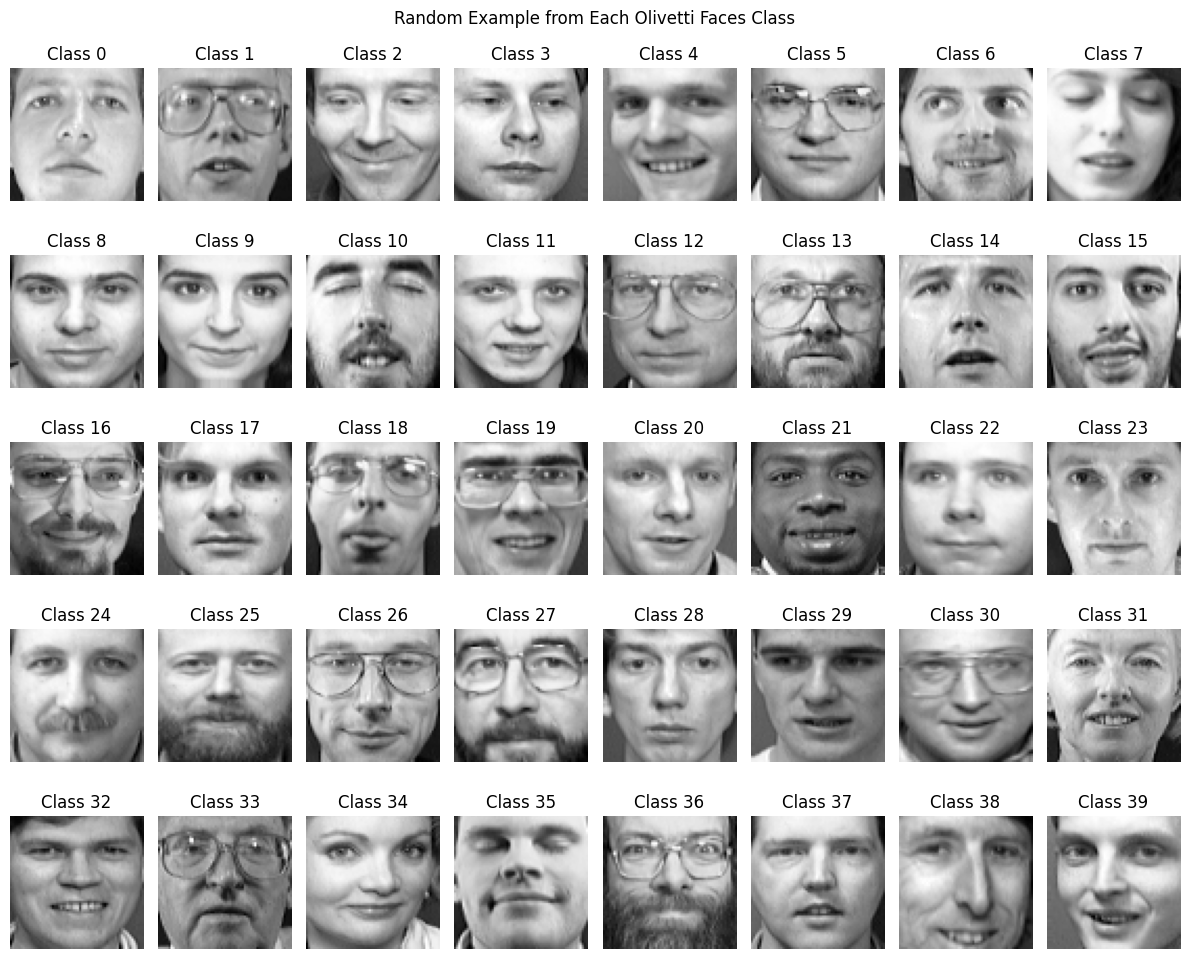

In [3]:
np.random.seed(42)

classes = np.unique(targets)
selected_indices = []

for class_label in classes:
    class_indices = np.where(targets == class_label)[0]
    random_index = np.random.choice(class_indices)
    selected_indices.append(random_index)

plt.figure(figsize=(12, 10))

for i, index in enumerate(selected_indices):
    plt.subplot(5, 8, i + 1)
    plt.imshow(data[index].reshape(64, 64), cmap="gray")
    plt.title(f"Class {targets[index]}")
    plt.axis("off")

plt.suptitle("Random Example from Each Olivetti Faces Class")
plt.tight_layout()
plt.show()

### 3. Fit Principal Component Analysis (PCA) on the full dataset using scikit-learn.

In [4]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(data)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components needed to retain at least 95% variance:", n_components_95)

Number of components needed to retain at least 95% variance: 123


### (a) Plot the cumulative explained variance ratio against the number of components. Choose a number of components that retains at least 95% of the variance and report this number.

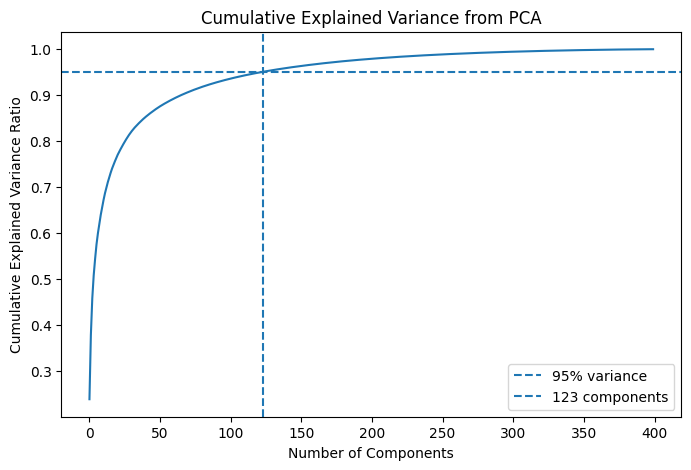

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(cumulative_variance)
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.axvline(x=n_components_95, linestyle="--", label=f"{n_components_95} components")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("Cumulative Explained Variance from PCA")
plt.legend()
plt.show()

blah

### (b) Display the first 10 principal components as 64 × 64 images. These are known as eigenfaces. Explain what these components represent and how they relate to the original images.

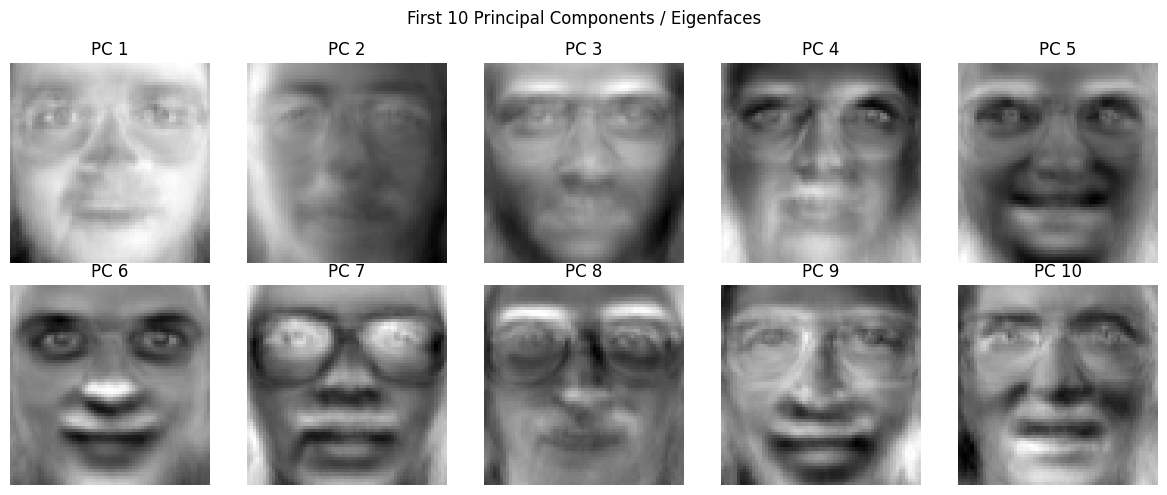

In [6]:
plt.figure(figsize=(12, 5))

for i in range(10):
    eigenface = pca.components_[i].reshape(64, 64)

    plt.subplot(2, 5, i + 1)
    plt.imshow(eigenface, cmap="gray")
    plt.title(f"PC {i + 1}")
    plt.axis("off")

plt.suptitle("First 10 Principal Components / Eigenfaces")
plt.tight_layout()
plt.show()

blah

### (c) Project the data onto the first two principal components and produce a scatter plot, colouring each point by its class. Comment on whether 2 components are sufficient to separate the classes.

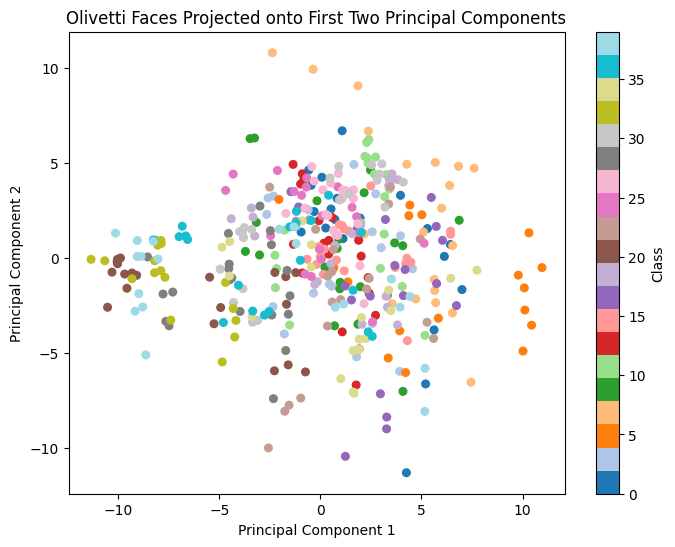

In [7]:
pca_2 = PCA(n_components=2)
data_2d = pca_2.fit_transform(data)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    data_2d[:, 0],
    data_2d[:, 1],
    c=targets,
    cmap="tab20",
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Olivetti Faces Projected onto First Two Principal Components")
plt.colorbar(scatter, label="Class")
plt.show()

The scatter plot shows the dataset projected onto the first two principal components. Each point represents one face image, and the colour represents the class label. The classes are not clearly separated using only two principal components. This suggests that two components are not enough to capture all the information needed to distinguish between the 40 different people. More components are likely needed for better separation.

### 4. Apply k-Means clustering to the original feature space. Use k equal to the number of classes.

### (a) Report the silhouette score of the clustering.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_original = KMeans(
    n_clusters=40,
    random_state=42,
    n_init=10
)

cluster_labels_original = kmeans_original.fit_predict(data)

silhouette_original = silhouette_score(data, cluster_labels_original)

print("Silhouette score for k-Means on original feature space:", silhouette_original)

Silhouette score for k-Means on original feature space: 0.14647039771080017


The silhouette score for k-Means on the original feature space is around 0.1465 as shown above. This suggests that the clusters are weakly separated with overlapping clusters. This low silhouette score is expected though because images of faces are high-dimensional and the real classes may not form simple clusters in the raw pixel space.

### (b) Visualise the cluster centroids as 64 × 64 images. Compare them to the eigenfaces from the previous task.

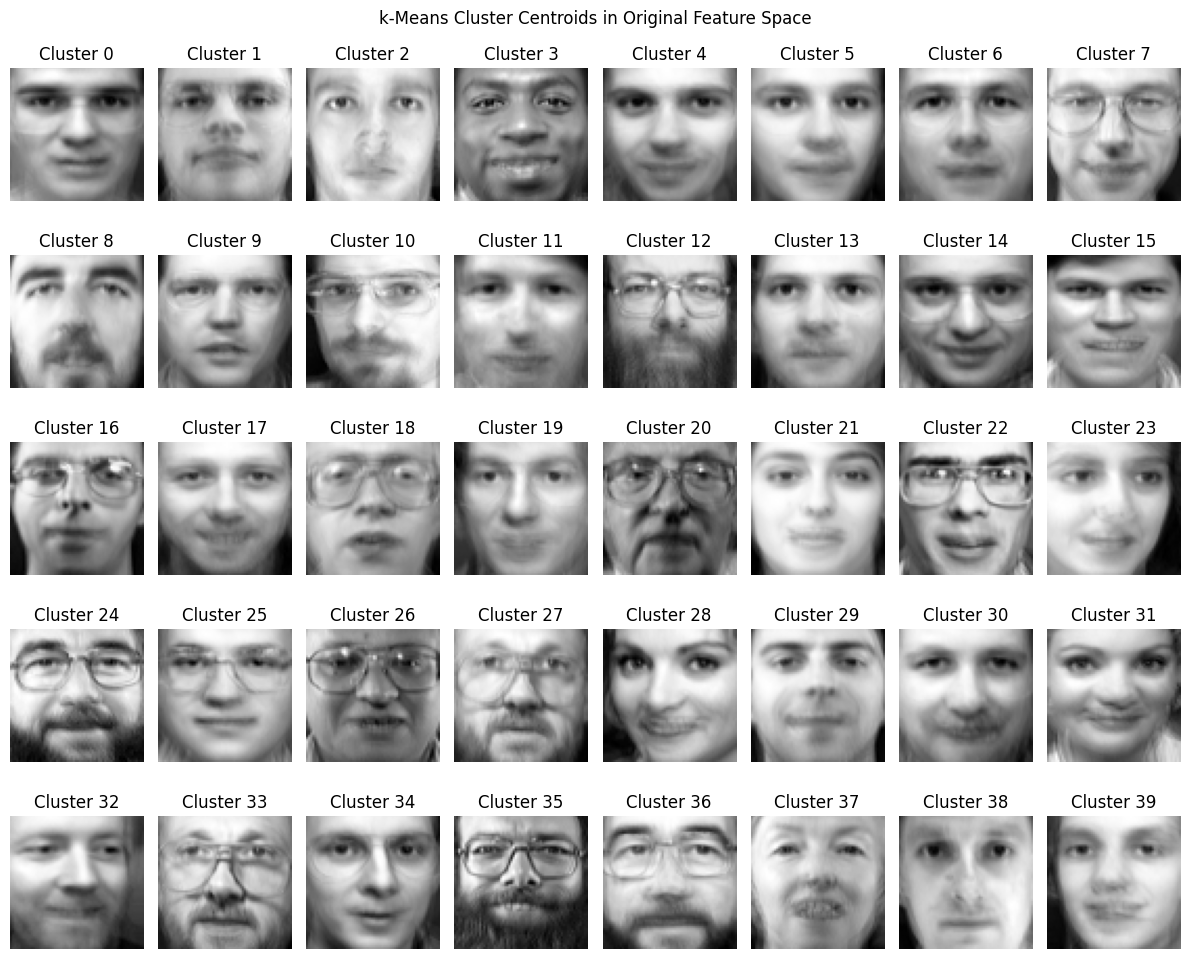

In [9]:
centroids_original = kmeans_original.cluster_centers_

plt.figure(figsize=(12, 10))

for i in range(40):
    plt.subplot(5, 8, i + 1)
    plt.imshow(centroids_original[i].reshape(64, 64), cmap="gray")
    plt.title(f"Cluster {i}")
    plt.axis("off")

plt.suptitle("k-Means Cluster Centroids in Original Feature Space")
plt.tight_layout()
plt.show()

The cluster centroids were reshaped into 64 × 64 images and displayed as face-like images. These centroids represent the average image for each cluster found by k-Means. They look more like blurred average faces than individual real faces, because each centroid is calculated by averaging the pixel values of all images assigned to that cluster.

Compared with the eigenfaces from the PCA section, the k-Means centroids are easier to interpret as average faces. The centroids represent the centre of each cluster in the original pixel space, so they look like blurry face images. In contrast, eigenfaces represent directions of variation in the dataset. They do not correspond to one cluster or one person, but instead show patterns such as lighting, shadows, and facial structure that explain variation across all images.

### 5. Repeat the k-Means clustering, this time on the PCA-reduced data.

### (a) Report the silhouette score for the PCA-reduced clustering.

In [10]:
pca_reduced = PCA(n_components=n_components_95)

data_pca_reduced = pca_reduced.fit_transform(data)

kmeans_pca = KMeans(
    n_clusters=40,
    random_state=42,
    n_init=10
)

cluster_labels_pca = kmeans_pca.fit_predict(data_pca_reduced)

silhouette_pca = silhouette_score(data_pca_reduced, cluster_labels_pca)

print("Silhouette score for k-Means on original feature space:", silhouette_original)
print("Silhouette score for k-Means on PCA-reduced data:", silhouette_pca)

Silhouette score for k-Means on original feature space: 0.14647039771080017
Silhouette score for k-Means on PCA-reduced data: 0.17436900734901428


I repeated k-Means clustering using the PCA-reduced version of the dataset. I used the number of principal components that retained at least 95% of the variance. This reduced the dimensionality of the data while preserving most of the original information.

### (b) Plot the silhouette diagrams for both the original and PCA-reduced clusterings, and compare them.

In [11]:
from sklearn.metrics import silhouette_samples

def plot_silhouette_diagram(X, cluster_labels, title):
    silhouette_values = silhouette_samples(X, cluster_labels)
    average_score = silhouette_score(X, cluster_labels)

    plt.figure(figsize=(10, 7))

    y_lower = 10

    for cluster in range(40):
        cluster_silhouette_values = silhouette_values[cluster_labels == cluster]
        cluster_silhouette_values.sort()

        cluster_size = cluster_silhouette_values.shape[0]
        y_upper = y_lower + cluster_size

        plt.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_silhouette_values
        )

        plt.text(-0.05, y_lower + 0.5 * cluster_size, str(cluster))

        y_lower = y_upper + 10

    plt.axvline(x=average_score, linestyle="--", label=f"Average = {average_score:.3f}")

    plt.xlabel("Silhouette coefficient")
    plt.ylabel("Cluster")
    plt.title(title)
    plt.legend()
    plt.show()

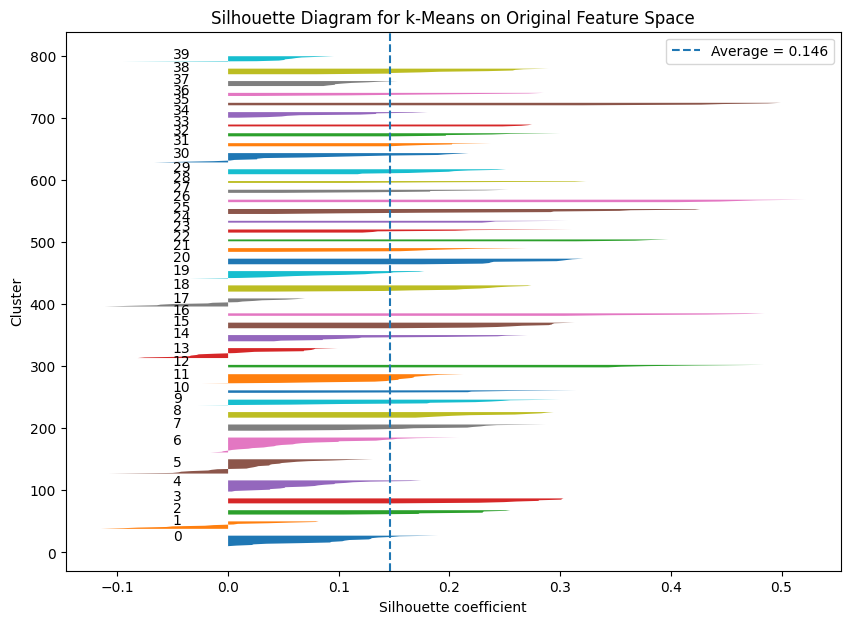

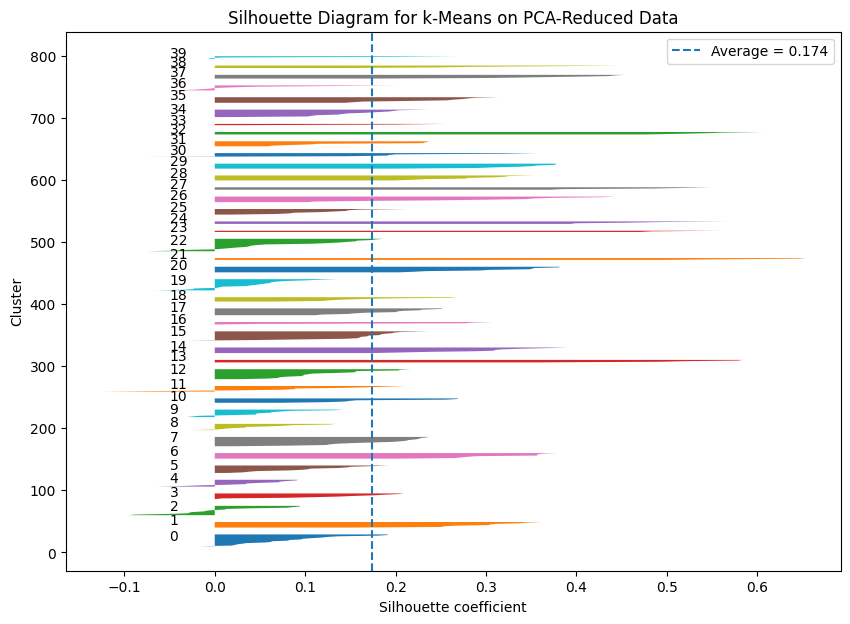

In [12]:
plot_silhouette_diagram(
    data,
    cluster_labels_original,
    "Silhouette Diagram for k-Means on Original Feature Space"
)

plot_silhouette_diagram(
    data_pca_reduced,
    cluster_labels_pca,
    "Silhouette Diagram for k-Means on PCA-Reduced Data"
)

The silhouette score for k-Means on the original feature space was [insert original score]. The silhouette score for k-Means on the PCA-reduced data was [insert PCA score].

The silhouette diagrams show how well each image fits within its assigned cluster. Wider positive regions indicate better-separated clusters, while values close to 0 indicate overlapping clusters. Negative values suggest that some images may have been assigned to the wrong cluster.

In this experiment, the silhouette scores were relatively low, which suggests that the face images do not form very clearly separated clusters. This is expected because the Olivetti Faces dataset contains images that may vary by lighting, pose and facial expression. Also, k-Means assumes roughly spherical clusters, which may not match the true structure of face image data.

Comparing the two diagrams, the PCA-reduced clustering [improved/did not improve] the silhouette score compared with the original feature space. PCA can help clustering by removing noise and reducing dimensionality, but it can also remove some information that may be useful for separating individual people. Therefore, the effect of PCA depends on whether the retained components capture the most useful differences between faces.